In [1]:
from anemone.experiment import *
from anemone.forwards import Forward, Forward3, ForwardLaplace4
from anemone.inversion import SmoothModel, Inversion
import torch
import matplotlib.pyplot as plt
import numpy as np


In [2]:
tx = Loop.square(40)
rx = Receiver()
times = torch.logspace(-5, -3, 51)
wv = Waveform.example()

In [3]:
fwr = ForwardLaplace4(tx, rx, times, waveform=wv)

c:\users\au646858\onedrive - aarhus universitet\documents\_repositories\anemone\src\anemone\experiment\experiment.py:129: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


In [4]:
sm = SmoothModel.starting_model(31)
rho,thick = sm.mod

dbdt = fwr(rho, thick)

In [5]:
inv = Inversion(dbdt, dbdt*0.05, sm, fwr, data_transform=torch.log10)

In [6]:
G0 = inv.jacobian(sm.vec)

In [7]:
plt.figure()
color=0
G = torch.empty(rho.shape+dbdt.shape, dtype=torch.float64)
for i in range(rho.shape[0]):
    drho = torch.log10(rho)
    drho[i] *= 1.02
    cdata = fwr(10**drho, thick)
    G[i] = (torch.log10(cdata)-torch.log10(dbdt))
    G[i] /= torch.log10(rho)[i]*0.02
    # plt.loglog(times, cdata-dbdt, f'C{color%9}')
    # plt.loglog(times, -(cdata-dbdt), f'C{color%9}--')
    # color += 1


<Figure size 640x480 with 0 Axes>

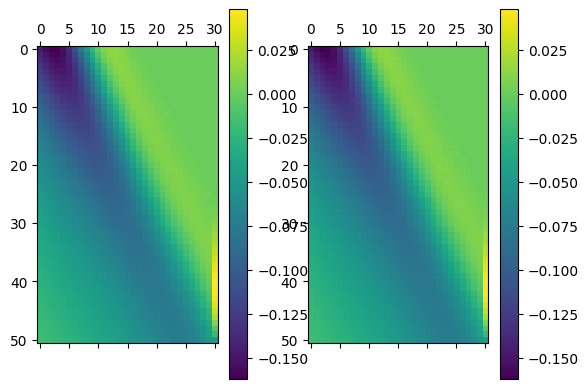

In [8]:
fig,axs = plt.subplots(1,2)
pcm=axs[0].matshow(G.T)
plt.colorbar(pcm, ax=axs[0])
pcm=axs[1].matshow(G0)
plt.colorbar(pcm, ax=axs[1])

In [9]:
from anemone.inversion import EarthModel
class SmoothMPA(EarthModel):
    def __init__(self, rho, phi_max, tau_phi, C, thick, device=None):
        lbnds = [torch.ones_like(rho)*1, torch.ones_like(phi_max)*1e-3, torch.ones_like(tau_phi)*1e-3, torch.ones_like(C)*1e-3]
        ubnds = [torch.ones_like(rho)*2e3, torch.ones_like(phi_max)*1e3, torch.ones_like(tau_phi)*1e3, torch.ones_like(C)*1e3]
        super().__init__([rho, phi_max, tau_phi, C], ['resistivity', 'phi_max', 'tau_phi', 'C'], lower_bounds=lbnds, upper_bounds=ubnds, device=device)
        self.n_layers = len(rho)
        self.thick = thick
        if device is not None:
            for attr_name in self.__dict__:
                attr_value = getattr(self, attr_name)
                if torch.is_tensor(attr_value):
                    setattr(self, attr_name, attr_value.to(device))
        self.device=device

    
    @classmethod
    def starting_model(cls, n_layers, depth_bottom=150, rho=40, phi_max=3e-4, tau_phi=3e-3, C=0.6, **kwargs):
        res      = rho*torch.ones(n_layers)
        phi_max  = phi_max*torch.ones(n_layers)
        tau_phi  = tau_phi*torch.ones(n_layers)
        C        = C*torch.ones(n_layers)
        thick    = torch.logspace(0, 1, n_layers-1)
        thick   *= depth_bottom/thick.sum()
        return cls(res, phi_max, tau_phi, C, thick, **kwargs)
    
    
    @staticmethod
    def vectorize(list_of_arrays):
        return torch.log10(torch.concat(list_of_arrays))

    def modelize(self, mvec):
        lin_mvec = 10**mvec
        rho      = lin_mvec[:self.n_layers]
        phi_max  = lin_mvec[self.n_layers:2*self.n_layers]
        tau_phi  = lin_mvec[2*self.n_layers:3*self.n_layers]
        c        = lin_mvec[3*self.n_layers:4*self.n_layers]
        return rho, phi_max, tau_phi, c, self.thick
    
    def make_physical(self,mvec):
        new_mvec = torch.clip(mvec, self.lbnds, self.ubnds)
        return new_mvec

    def plot(self, axs=None, **kwargs):
        thk = self.thick
        if axs is None:
            from matplotlib.pyplot import subplots
            fig,axs = subplots(1,4, sharey=True)
        for v,ax,pname in zip(self.values, axs, self.names):
            z1 = np.cumsum(thk.numpy())
            z2 = np.zeros((len(z1)+1,2))
            z2[1:,0]=z1
            z2[:-1,1]=z1
            z2[-1,1] = z1.max()*1.5
            v2 = np.repeat(v.numpy(), 2).T
            
            ax.plot(v2.flatten(), z2.flatten(), **kwargs)
            ax.set_title(pname)
        axs[0].set_ylim(z2.max(), z2.min())
        axs[0].set_ylabel('depth [m]')
        return axs
    
    @property
    def colecole(self):
        rho, phi_max, tau_phi, c = self.values
        from anemone.physics import mpa2colecole
        from anemone.inversion import SmoothModelColeCole
        rho, m, tau, c = mpa2colecole(rho, phi_max, tau_phi, c)
        return SmoothModelColeCole(rho, m, tau, c, self.thick, device=self.device)

In [10]:
fwr_mpa = ForwardLaplace4.mpa(tx, rx, times, waveform=wv)

In [11]:
mpa_mtrue = SmoothMPA(torch.tensor([50, 130, 30]),
                      torch.tensor([134., 400., 24.])*1e-4,
                      torch.tensor([1.5, 2.5, 3.5])*1e-3,
                      torch.tensor([0.6, 0.5, 0.4]),
                      torch.tensor([20, 30]))
dbdt = fwr_mpa(*mpa_mtrue.mod)

In [12]:
cc_mtrue = mpa_mtrue.colecole
fwr_cc = ForwardLaplace4.colecole(tx, rx, times, waveform=wv)

array([<Axes: title={'center': 'resistivity'}, ylabel='depth [m]'>,
       <Axes: title={'center': 'tau'}>,
       <Axes: title={'center': 'chargeability'}>,
       <Axes: title={'center': 'c'}>], dtype=object)

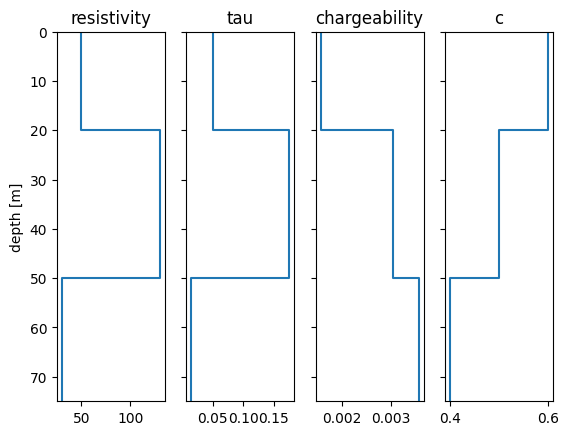

In [13]:
cc_mtrue.plot()

In [14]:
dbdt_cc = fwr_cc(*cc_mtrue.mod)

False


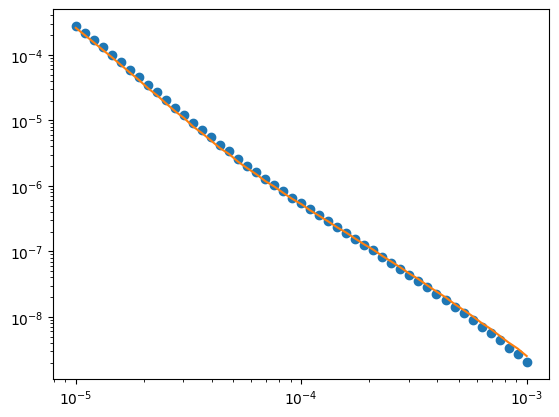

In [15]:
dbdt_res = fwr(torch.tensor([50., 130., 30.]), torch.tensor([20, 30]))

print(torch.allclose(dbdt, dbdt_res))

plt.figure()
plt.loglog(times, dbdt_cc, 'o')
plt.loglog(times, dbdt_res)

In [22]:
mpa_sm = SmoothMPA.starting_model(31, rho=100, phi_max=1e-2, tau_phi=1e-2, C=1e-1)
inv = Inversion(dbdt, dbdt*0.05, mpa_sm, fwr_mpa)
# G_mpa = inv.jacobian(mpa_sm.vec)

In [23]:
results = inv.invert(smoothness=10)

001	misfit:	0.00
002	misfit:	0.00

 2


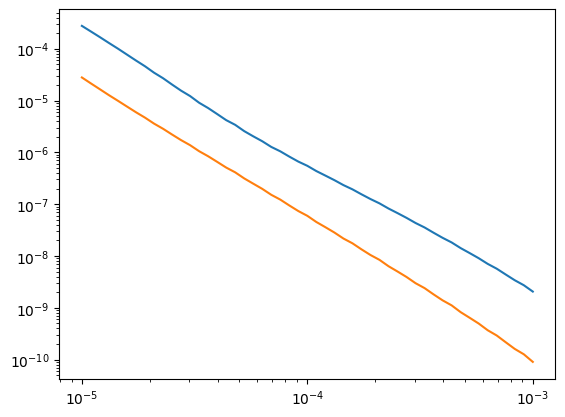

In [24]:
dpred = fwr_mpa(*results.mod)

plt.figure()
plt.loglog(times, dbdt)
plt.loglog(times, dpred)

In [25]:
mvec_st = mpa_sm.vec
cmod = mpa_sm.modelize(mvec_st)
mvec_st1 = mpa_sm.vectorize(cmod[:-1])

In [26]:
G_mpa = inv.jacobian(mpa_sm.vec)

In [27]:
torch.allclose(mvec_st, mvec_st1)

True

array([<Axes: title={'center': 'resistivity'}, ylabel='depth [m]'>,
       <Axes: title={'center': 'phi_max'}>,
       <Axes: title={'center': 'tau_phi'}>, <Axes: title={'center': 'C'}>],
      dtype=object)

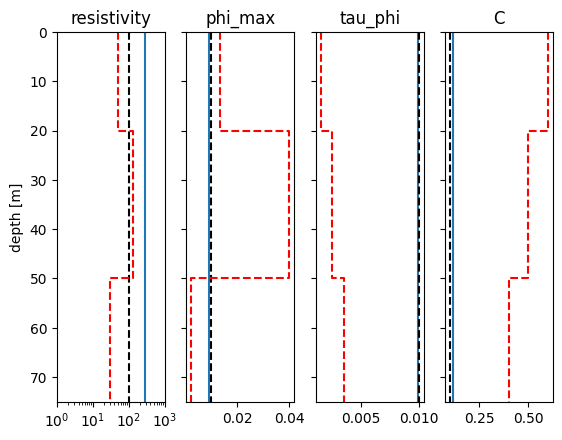

In [28]:
axs = results.plot()
mpa_sm.plot(axs=axs, color='k', linestyle='--')
axs[0].set_xlim(1, 1000); axs[0].set_xscale('log')
mpa_mtrue.plot(axs=axs, color='r', linestyle='--')
# sm.plot(ax=axs[0], color='r', linestyle='--')

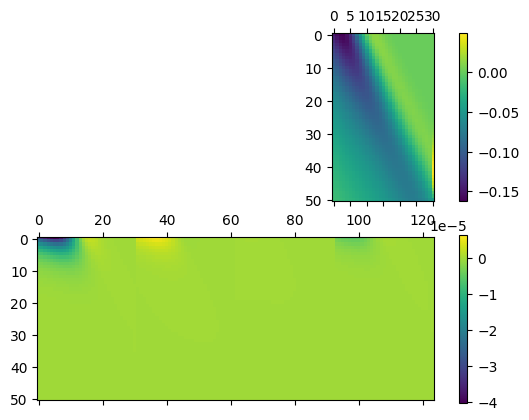

In [29]:
fig,axs = plt.subplots(2,1)
pcm=axs[0].matshow(G0)
plt.colorbar(pcm, ax=axs[0])
pcm=axs[1].matshow(G_mpa)
plt.colorbar(pcm, ax=axs[1])